# **Employee Attrition Prediction using Logistic Regression**

---



## 1. Business problem

When an employee leaves, the company has to spend time and money to hire and train someone new, and the team's work slows down. If HR knew early which employees are likely to leave, they could talk to them and try to fix the problem in time.

In this project I build a model that gives the chance of an employee leaving, using details like income, overtime, job role and experience.

**Target:** `Attrition` (Yes = left, No = stayed)
**Problem type:** binary classification

## Step 1: Import Libraries and Load Data

First I import the libraries I need and load the dataset.

In [182]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [183]:
df= pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

## Step 2: Understanding the Data

Before doing anything, I look at the data: how big it is, what the columns are, and whether anything is missing.

In [184]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [185]:
df.shape

(1470, 35)

In [186]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [187]:
print('Null values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())

Null values: 0
Duplicate rows: 0


The dataset has 1,470 rows and 35 columns. There are no null values and no duplicate rows, so I did not need to fix any missing data. Nine columns are text and the rest are numbers.

## Step 3: Checking the Target

The target is `Attrition`. I check how many employees left and how many stayed.

In [188]:
print(df['Attrition'].value_counts())
print()
print(df['Attrition'].value_counts(normalize=True) * 100)

Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


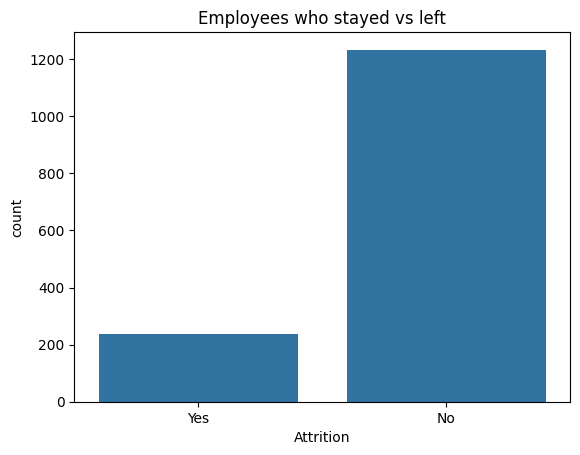

In [189]:
sns.countplot(x=df['Attrition'])
plt.title('Employees who stayed vs left')
plt.show()

Only about 16% of the employees left (237 out of 1,470), so the data is imbalanced.

This matters because accuracy can fool me here. A model that says "stays" for every employee would already be 84% correct and would not find a single leaver. So I will mainly look at precision, recall and F1 for the leaving class.

## Step 4: Cleaning the Data

I check which columns are useful. A column that is the same for everyone, or different for everyone, cannot help the model.

In [190]:
df.nunique().sort_values()

,0
EmployeeCount,1
Over18,1
StandardHours,1
Attrition,2
OverTime,2
PerformanceRating,2
Gender,2
BusinessTravel,3
Department,3
MaritalStatus,3


Four columns are not useful:

- `EmployeeNumber` has a different value for every employee (1,470 values for 1,470 rows), so it is just an ID.
- `EmployeeCount`, `Over18` and `StandardHours` have the same value for every employee.

None of these can help the model separate leavers from stayers, so I dropped them.

## Data Cleaning

In [191]:
df = df.drop(columns=['EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours'])
df.shape

(1470, 31)

## Step 5: Exploring the Data

I compare a few columns with `Attrition` to see which employees leave more often.

### Overtime

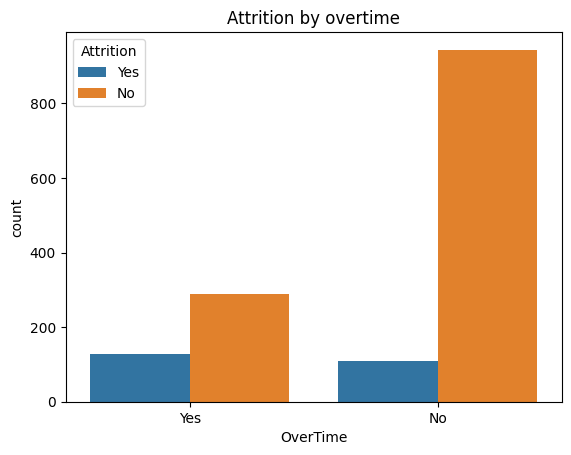

In [192]:
sns.countplot(x=df['OverTime'], hue=df['Attrition'])
plt.title('Attrition by overtime')
plt.show()

In [193]:
pd.crosstab(df['OverTime'], df['Attrition'], normalize='index') * 100

Attrition,No,Yes
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


In the plot the number of leavers looks similar in both groups, but the group without overtime is much bigger. That is why I checked the rate instead of the count.

30.5% of the employees who work overtime left, compared with 10.4% of those who do not. So employees doing overtime leave almost 3 times more often.

### Monthly income

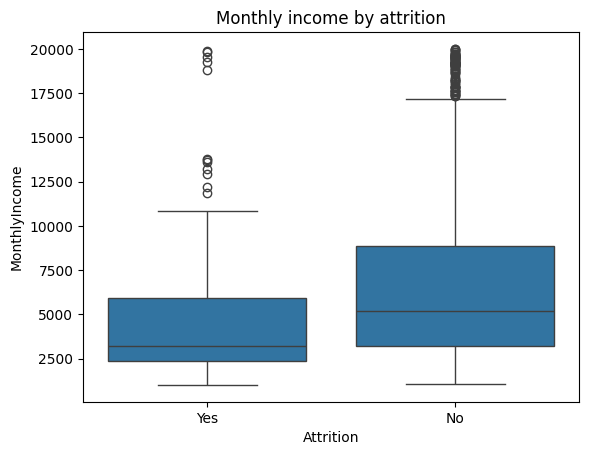

In [194]:
sns.boxplot(x=df['Attrition'], y=df['MonthlyIncome'])
plt.title('Monthly income by attrition')
plt.show()

In [195]:
df.groupby('Attrition')['MonthlyIncome'].median()

,MonthlyIncome
Attrition,
No,5204.0
Yes,3202.0


Employees who left earn less. The median income is 3,202 for leavers and 5,204 for stayers. Both groups have some high-income outliers, but there are many more in the group that stayed. I used the median because a few very high salaries pull the mean up.

### Experience

In [196]:
df.groupby('Attrition')['TotalWorkingYears'].median()

,TotalWorkingYears
Attrition,
No,10.0
Yes,7.0


In [197]:
df[['MonthlyIncome', 'TotalWorkingYears']].corr()

,MonthlyIncome,TotalWorkingYears
MonthlyIncome,1.000000,0.772893
TotalWorkingYears,0.772893,1.000000


Leavers also have less experience: the median is 7 working years for leavers and 10 for stayers. Income and working years are strongly correlated (0.77), so part of the lower income of leavers may simply be because they are early in their careers.

This shows a link, not a cause. I keep both columns for now, because 0.77 is high but not extreme.

## Step 6: Preparing the Data

The model needs numbers, so I convert the text columns.

- **Attrition:** Yes = 1 and No = 0. I gave 1 to the leavers because they are the group I want the model to find, so precision and recall will be about them.
- **Gender and OverTime:** only two values each, so I mapped them to 0 and 1 (Female = 1, Male = 0, and Yes = 1, No = 0).
- **Other five text columns:** these have 3 to 9 values each, so I used one-hot encoding with `drop_first=True`. Dropping one column avoids the dummy variable trap, where one column can be calculated from the others.

In [198]:
df['Attrition'] = df['Attrition'].map({'Yes': 1, 'No': 0})
df['Gender'] = df['Gender'].map({'Female': 1, 'Male': 0})
df['OverTime'] = df['OverTime'].map({'Yes': 1, 'No': 0})

df['Attrition'].value_counts()

,count
Attrition,
0,1233
1,237


In [199]:
text_cols = df.select_dtypes(include='object').columns.tolist()
print(text_cols)

df = pd.get_dummies(df, columns=text_cols, drop_first=True, dtype=int)
df.shape

['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']


(1470, 45)

After encoding there are 45 columns: 44 features and the target.

## Step 7: Train and Test Split

I keep 20% of the data aside as a test set. The model never sees it during training, so the test score shows how it will work on new employees.

I used `stratify=y` because only 16% of the employees left. A normal random split could give the test set too few or too many leavers by chance. With `stratify`, both train and test keep about 16% leavers.

In [200]:
from sklearn.model_selection import train_test_split

In [201]:
X = df.drop(columns=['Attrition'])
y = df['Attrition']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Leavers in train:', round(y_train.mean() * 100, 1), '%')
print('Leavers in test: ', round(y_test.mean() * 100, 1), '%')

Train: (1176, 44)  Test: (294, 44)
Leavers in train: 16.2 %
Leavers in test:  16.0 %


## Step 8: Scaling

Columns like `MonthlyIncome` are in thousands, while columns like `JobLevel` go from 1 to 5. I used `StandardScaler` so all columns are on a similar scale.

I fitted the scaler on the training data only and then used it to transform the test data. If I had fitted it on all the data, information from the test set would leak into training.

In [202]:
from sklearn.preprocessing import StandardScaler

In [203]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Step 9: Model 1, Logistic Regression

Now I train the first model. Logistic regression gives the chance (from 0 to 1) that an employee leaves. If the chance is above 0.5, the model predicts "will leave".

In [204]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [205]:
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))

Accuracy: 0.8605


In [206]:
labels = ['Actually stayed', 'Actually left']
pred_labels = ['Predicted stayed', 'Predicted left']

pd.DataFrame(confusion_matrix(y_test, y_pred), index=labels, columns=pred_labels)

,Predicted stayed,Predicted left
Actually stayed,237,10
Actually left,31,16


In [207]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.96      0.92       247
           1       0.62      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.75      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294



Accuracy is 86%, but that number hides the problem. The test set has 47 employees who left, and the model found only 16 of them (recall 0.34). It missed 31. When it did say "will leave", it was right 62% of the time (precision 0.62).

A model that always says "stays" gets 84%, so 86% is only a small improvement.

## Step 10: Model 2, Handling the Imbalance

To make the model pay more attention to the employees who leave, I used `class_weight='balanced'`. This makes a mistake on a leaver count more than a mistake on a stayer.

In [208]:
log_reg_bal = LogisticRegression(class_weight='balanced', random_state=42)
log_reg_bal.fit(X_train_scaled, y_train)

y_pred_bal = log_reg_bal.predict(X_test_scaled)
print('Accuracy:', round(accuracy_score(y_test, y_pred_bal), 4))

Accuracy: 0.7517


In [209]:
pd.DataFrame(confusion_matrix(y_test, y_pred_bal), index=labels, columns=pred_labels)

,Predicted stayed,Predicted left
Actually stayed,192,55
Actually left,18,29


In [210]:
print(classification_report(y_test, y_pred_bal))

              precision    recall  f1-score   support

           0       0.91      0.78      0.84       247
           1       0.35      0.62      0.44        47

    accuracy                           0.75       294
   macro avg       0.63      0.70      0.64       294
weighted avg       0.82      0.75      0.78       294



## Step 11: Results

Scores for the leaving class (1) on the test set:

| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Logistic Regression (default) | 0.86 | 0.62 | 0.34 | 0.44 |
| Logistic Regression (balanced) | 0.75 | 0.35 | 0.62 | 0.44 |

With balanced weights, recall went up from 0.34 to 0.62, so the model now finds about 29 of the 47 leavers instead of 16. But precision dropped from 0.62 to 0.35, so many of the employees it flags will not actually leave. Accuracy also went down because the model now makes more mistakes on the employees who stayed. F1 stayed the same.

## Conclusion

- Employees who work overtime, earn less and have fewer working years are more likely to leave.
- Accuracy alone is misleading for this data, because only 16% of the employees left.
- Which model is better depends on what HR does with a flagged employee. If it is only a friendly conversation, missing a leaver costs more than a false alarm, so the balanced model is more useful. If it is an expensive retention offer, a model with higher precision is better.

**Limitations:** the test set has only 47 leavers, so the scores can change with a different split. The data also does not say why people left.